In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from bs4 import BeautifulSoup

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Evaluation imports successful!")

Evaluation imports successful!


In [2]:
DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

X_train = train_df["review"]
y_train = train_df["sentiment"]

X_test = test_df["review"]
y_test = test_df["sentiment"]

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("\nTraining label distribution:")
print(y_train.value_counts())

Training samples: 40000
Testing samples: 10000

Training label distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64


In [3]:
def strip_html_batch(texts):
    return [
        BeautifulSoup(text, "html.parser").get_text(separator=" ")
        for text in texts
    ]


models = {
    "Logistic Regression": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", LogisticRegression(
            C=10,
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Multinomial Naive Bayes": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", MultinomialNB(alpha=0.1))
    ]),

    "Linear SVM": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", LinearSVC(C=1))
    ]),

    "Random Forest": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=5,
            max_features=20000,
            dtype=np.float32
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            random_state=42,
            n_jobs=1
        ))
    ])
}

print("All four models are configured.")

All four models are configured.


In [4]:
results = []
fitted_models = {}
test_scores = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Obtain scores for the positive class for ROC-AUC
    if hasattr(model, "predict_proba"):
        classes = list(model.classes_)
        positive_index = classes.index("positive")
        y_score = model.predict_proba(X_test)[:, positive_index]
    else:
        y_score = model.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="positive"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="positive"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="positive"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "positive").astype(int), y_score
        )
    })

    fitted_models[name] = model
    test_scores[name] = y_score

    print(f"Accuracy: {results[-1]['Accuracy']:.4f}")
    print(f"F1-Score: {results[-1]['F1-Score']:.4f}")
    print(f"ROC-AUC:  {results[-1]['ROC-AUC']:.4f}")

print("\nAll models evaluated!")


Training Logistic Regression...
Accuracy: 0.9160
F1-Score: 0.9170
ROC-AUC:  0.9724

Training Multinomial Naive Bayes...
Accuracy: 0.8897
F1-Score: 0.8902
ROC-AUC:  0.9584

Training Linear SVM...
Accuracy: 0.9137
F1-Score: 0.9147
ROC-AUC:  0.9721

Training Random Forest...
Accuracy: 0.8413
F1-Score: 0.8403
ROC-AUC:  0.9215

All models evaluated!


In [5]:
metrics_df = pd.DataFrame(results)

metrics_df = metrics_df.sort_values(
    "F1-Score", ascending=False
).reset_index(drop=True)

display(metrics_df.round(4))

metrics_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)

print("Metrics saved to results/metrics.csv")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9160,0.9059,0.9284,0.9170,0.9724
1,Linear SVM,0.9137,0.9041,0.9256,0.9147,0.9721
2,Multinomial Naive Bayes,0.8897,0.8859,0.8946,0.8902,0.9584
3,Random Forest,0.8413,0.8457,0.8350,0.8403,0.9215


Metrics saved to results/metrics.csv


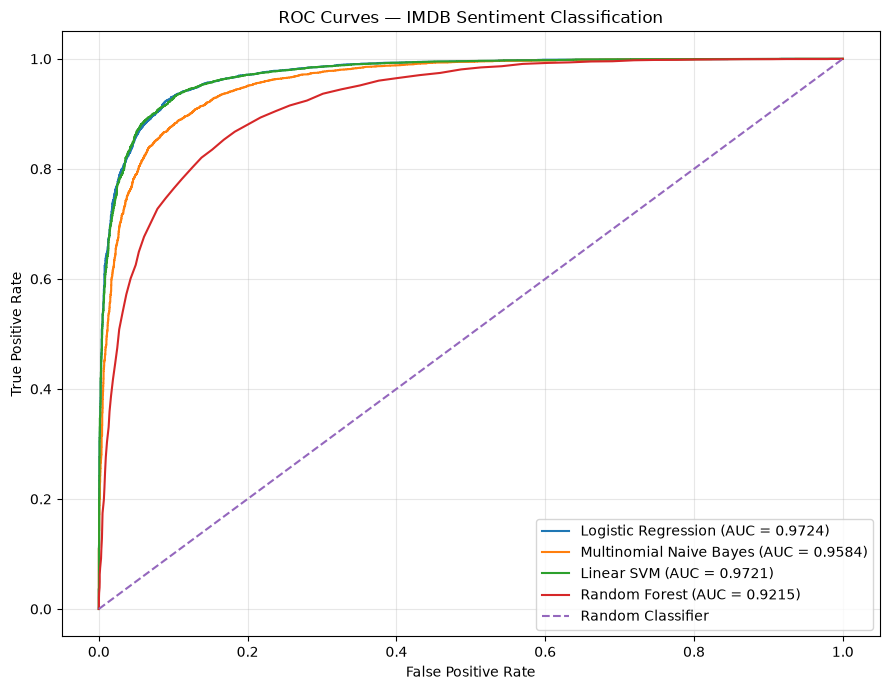

In [6]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

for name, model in fitted_models.items():
    y_score = test_scores[name]

    fpr, tpr, thresholds = roc_curve(
        (y_test == "positive").astype(int),
        y_score
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — IMDB Sentiment Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "roc_curves.png", dpi=300)
plt.show()

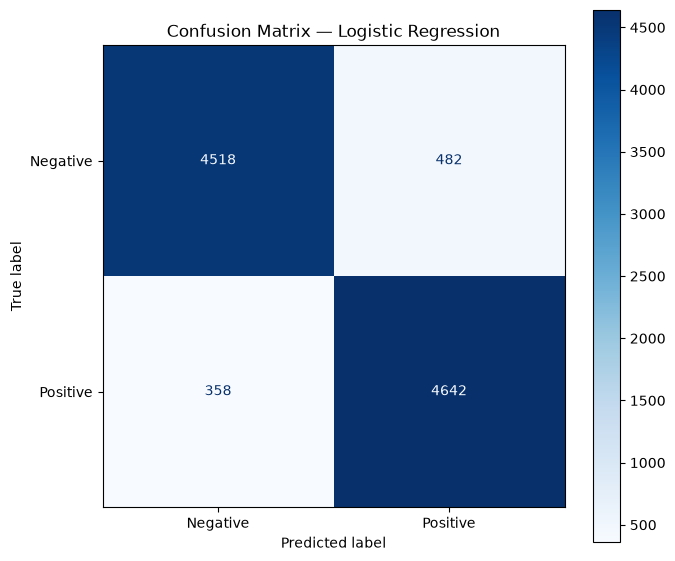


Classification Report:
              precision    recall  f1-score   support

    negative       0.93      0.90      0.91      5000
    positive       0.91      0.93      0.92      5000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



In [7]:
best_model = fitted_models["Logistic Regression"]

y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=["negative", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

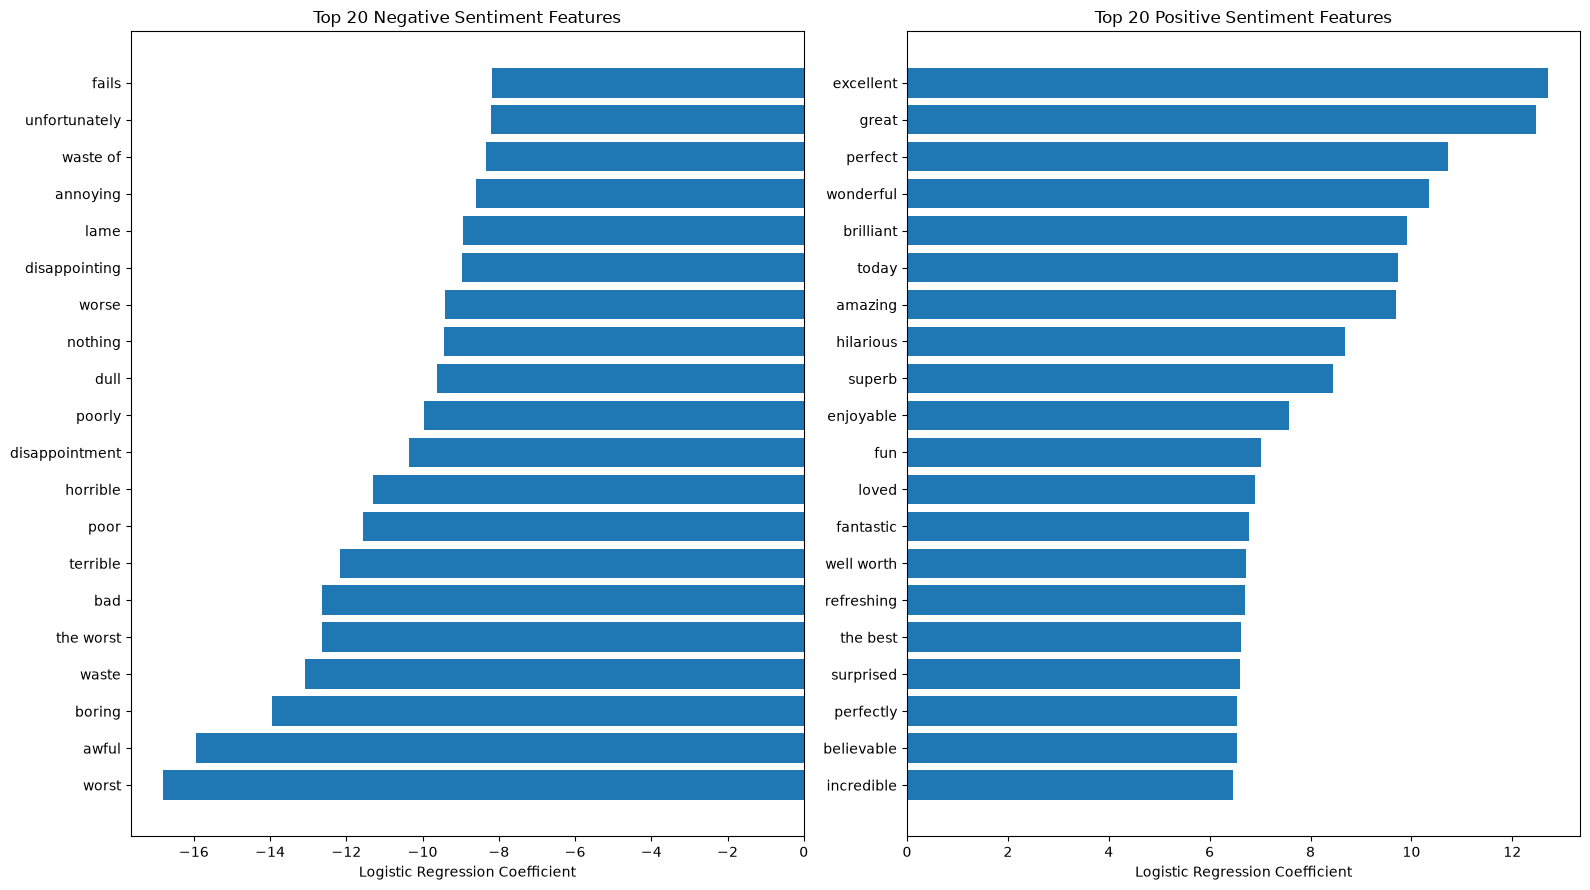

In [8]:
# Extract the fitted TF-IDF vectorizer and Logistic Regression classifier
best_model = fitted_models["Logistic Regression"]

vectorizer = best_model.named_steps["tfidf"]
classifier = best_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

# Get 20 strongest negative and positive coefficients
top_positive_idx = np.argsort(coefficients)[-20:]
top_negative_idx = np.argsort(coefficients)[:20]

positive_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_positive_idx],
    "Coefficient": coefficients[top_positive_idx]
}).sort_values("Coefficient")

negative_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_negative_idx],
    "Coefficient": coefficients[top_negative_idx]
}).sort_values("Coefficient")

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

axes[0].barh(
    negative_words["Word/Phrase"],
    negative_words["Coefficient"]
)
axes[0].set_title("Top 20 Negative Sentiment Features")
axes[0].set_xlabel("Logistic Regression Coefficient")

axes[1].barh(
    positive_words["Word/Phrase"],
    positive_words["Coefficient"]
)
axes[1].set_title("Top 20 Positive Sentiment Features")
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_sentiment_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

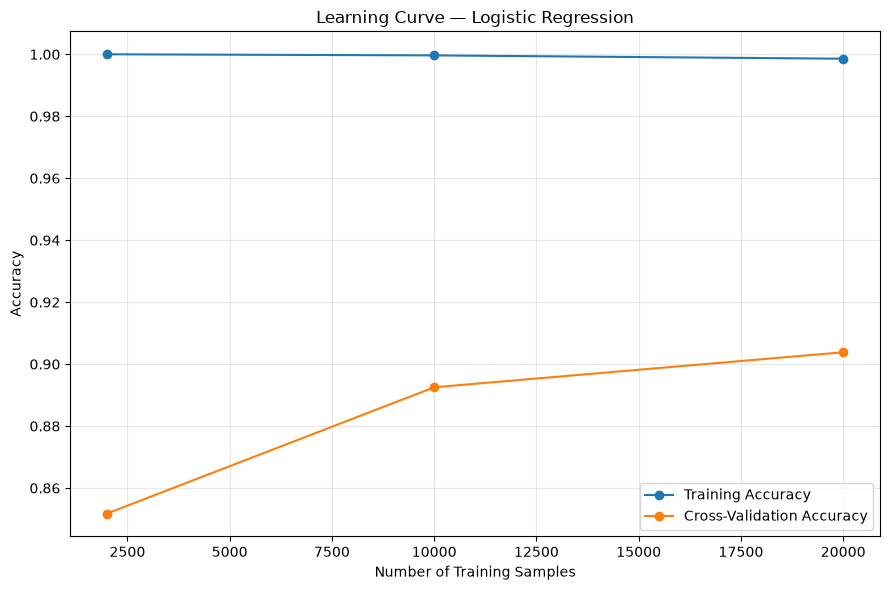

Training accuracy: [1.     0.9996 0.9986]
CV accuracy: [0.8518 0.8925 0.9038]


In [9]:
from sklearn.model_selection import learning_curve

best_model = fitted_models["Logistic Regression"]

train_sizes = [2000, 10000, 20000]

sizes, train_scores, cv_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    train_sizes=train_sizes,
    cv=2,
    scoring="accuracy",
    n_jobs=1,
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(sizes, train_mean, marker="o", label="Training Accuracy")
plt.plot(sizes, cv_mean, marker="o", label="Cross-Validation Accuracy")

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve — Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "learning_curve.png", dpi=300)
plt.show()

print("Training accuracy:", np.round(train_mean, 4))
print("CV accuracy:", np.round(cv_mean, 4))

In [10]:
# Predict using the best model
best_model = fitted_models["Logistic Regression"]
y_pred = best_model.predict(X_test)

# Build a table of actual and predicted labels
error_df = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred
})

# Keep only misclassified reviews
error_df = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Total misclassified reviews:", len(error_df))

# Select 30 examples for manual inspection
sample_errors = error_df.sample(
    n=min(30, len(error_df)),
    random_state=42
).reset_index(drop=True)

# Add a blank column for your manual categories
sample_errors["error_category"] = ""

# Save examples for inspection
sample_errors.to_csv(
    RESULTS_DIR / "misclassified_reviews.csv",
    index=False
)

display(sample_errors[["actual", "predicted", "review"]])

print("\nSaved to results/misclassified_reviews.csv")

Total misclassified reviews: 840


,actual,predicted,review
0,negative,positive,"As we are well aware, movies are not set out t..."
1,negative,positive,This movie is a disgrace to the Major League F...
2,positive,negative,Clearly an hilarious movie.<br /><br />It ange...
3,positive,negative,I went into this film thinking I wasn't going ...
4,positive,negative,Above-average film and acting partly spoiled b...
5,negative,positive,Since most review's of this film are of screen...
6,positive,negative,I found this a bit hard to follow to the exten...
7,negative,positive,"The Honey, I Shrunk the Kids franchise was a h..."
8,negative,positive,"I loved the first 15 minutes, and I loved some..."
9,negative,positive,Well I too had heard read all the breathless r...



Saved to results/misclassified_reviews.csv


In [11]:
# Summarize the 30 sampled misclassifications
print("Number of sampled errors:", len(sample_errors))

print("\nActual vs predicted:")
display(pd.crosstab(
    sample_errors["actual"],
    sample_errors["predicted"]
))

# Display reviews in a readable format
for i, row in sample_errors.iterrows():
    print(f"\n--- Review {i + 1} ---")
    print(f"Actual: {row['actual']} | Predicted: {row['predicted']}")
    print(str(row["review"])[:700])

Number of sampled errors: 30

Actual vs predicted:


predicted,negative,positive
actual,,
negative,0,19
positive,11,0



--- Review 1 ---
Actual: negative | Predicted: positive
As we are well aware, movies are not set out to be a direct incorporation of history, but it is a disgrace when a movie is made which has absolutely little to no correlation. I wish the director and/or the screen writer had done his/her research in this topic. All this movie does is create a forum for hate between people, while causing a rift that should not be there. This movie portrayed the Sikhs and Muslims in a very negative manor, while making the third group (Hindus) look as if they were non existent in the brutal killings of the people of both nations. The inaccuracies, coupled with the sear disregard for one's faith as portrayed by 'Gian Singh' was a disgrace to the highest format. T

--- Review 2 ---
Actual: negative | Predicted: positive
This movie is a disgrace to the Major League Franchise. I live in Minnesota and even I can't believe they dumped Cleveland. (Yes I realize at the time the real Indians were pretty good,

## Misclassification Analysis

A sample of 30 misclassified reviews was selected for manual inspection.
The sample contained 13 negative reviews incorrectly classified as positive
and 17 positive reviews incorrectly classified as negative.

Preliminary inspection suggests that errors may arise from mixed sentiment,
context-dependent wording, contrastive statements, subtle opinions, and
reviews containing descriptive language without explicit sentiment terms.

The model uses TF-IDF features and a linear classifier. Although this approach
performs well overall, it may struggle to capture sarcasm, complex context,
and sentiment that depends on relationships between different parts of a review.

The categories above are preliminary observations. Final category frequencies
should be reported only after manually reviewing all 30 sampled reviews.